## Projet: Détection de fraude (modelisation)
Le but de ce projet est de prédire la probabilité qu'une transaction en ligne soit frauduleuse en utilisant l'apprentissage automatique.

### Etape1: Prétraitement des données

Le prétraitement des donnnées consiste à télécharger les données, comprendre le dataset, le nettoyer, le modéliser et faire du feature engineering(créer des nouvelles features ou colonnes).


In [1]:
#téléchargement des librairies

#manipulation de données
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import kaggle

#modélisation
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA

#analyse statistique
import statsmodels.api as sm

#entrainement des modèles de machine learning
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor

#évaluation des modèles
from sklearn.metrics import mean_squared_error, r2_score ,confusion_matrix, classification_report

In [2]:
#dataset
identity = pd.read_csv(r"C:\Users\lucre\Desktop\Projet_Perso\Detection_de_fraude\iee_ics_data\train_identity.csv")
transaction = pd.read_csv(r"C:\Users\lucre\Desktop\Projet_Perso\Detection_de_fraude\iee_ics_data\train_transaction.csv")

In [3]:
identity.head()

,TransactionID,id_01,id_02,id_03,id_04,id_05,id_06,id_07,id_08,id_09,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0.0,70787.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,-5.0,98945.0,NaN,NaN,0.0,-5.0,NaN,NaN,NaN,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,-5.0,191631.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,-5.0,221832.0,NaN,NaN,0.0,-6.0,NaN,NaN,NaN,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0.0,7460.0,0.0,0.0,1.0,0.0,NaN,NaN,0.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


In [4]:
transaction.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,V330,V331,V332,V333,V334,V335,V336,V337,V338,V339
0,2987000,0,86400,68.5,W,13926,NaN,150.0,discover,142.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2987001,0,86401,29.0,W,2755,404.0,150.0,mastercard,102.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2987002,0,86469,59.0,W,4663,490.0,150.0,visa,166.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2987003,0,86499,50.0,W,18132,567.0,150.0,mastercard,117.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,2987004,0,86506,50.0,H,4497,514.0,150.0,mastercard,102.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [5]:
data = pd.merge(transaction, identity, on='TransactionID', how='inner')
data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0,86506,50.000,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,0,86535,15.000,H,2803,100.0,150.0,visa,226.0,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,0,86549,75.887,C,16496,352.0,117.0,mastercard,134.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,Windows
3,2987011,0,86555,16.495,C,4461,375.0,185.0,mastercard,224.0,...,chrome 62.0,NaN,NaN,NaN,F,F,T,T,desktop,NaN
4,2987016,0,86620,30.000,H,1790,555.0,150.0,visa,226.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


### Informations sur les tables de données

La table transaction contient regroupent toutes les transactions(envoi d'argent, achats de bien et service) et la table identité regroupent les informations d'identité, de connexion réseau (IP,FAI,proxy,etc) associées aux transactions et la signature numérique(UA/navigateur/OS/version,etc). Toutes les transactions n'ont pas d'informations d'identité.

#### Table Transaction
- TransactionDT : delta temporelle d’une date de référence donnée (et non d’un horodatage réel)
- TransactionAMT : montant du paiement de la transaction en USD
ProductCD : code produit, le produit pour chaque transaction
- Carte1 - Carte6 : informations sur les cartes de paiement, telles que le type de carte, la catégorie de carte, la banque d’origine, le pays, etc.
- ADDR : Adresse
- dist : distance
- P_ et (R__) domaine email : domaine email acheteur et destinataire
- C1-C14 : comptage, comme le nombre d’adresses identifiées à la carte de paiement, etc. Le sens réel est masqué.
- D1-D15 : delta de temps, comme les jours entre les transactions précédentes, etc.
- M1-M9 : correspondance, comme les noms sur la carte et l’adresse, etc.
- Vxxx : Vesta a conçu des fonctionnalités riches, y compris le classement, le comptage et d’autres relations avec les entités.

#### Table Identity
Caractéristiques catégorielles : DeviceType DeviceInfo id_12 - id_38

In [6]:
##Exploration des données
data.info() #144233 lignes et 434 colonnes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144233 entries, 0 to 144232
Columns: 434 entries, TransactionID to DeviceInfo
dtypes: float64(399), int64(4), object(31)
memory usage: 477.6+ MB


In [7]:
#nombre de valeurs manquantes
data.isnull().sum().sort_values(ascending=False) #il y'a des données manquantes dans 434 colonnes
print("Proportions de valeurs manquantes sur l'ensemble des données : ", (data.isnull().sum().sum() / (data.shape[0] * data.shape[1])) * 100, "%")
#on a 27% des valeurs manquantes, ce qui est très elévé,on va donc amputer dans un premier temps les colonnes ayant plus de 50% de valeurs manquantes, puis on va imputer les colonnes restantes avec la moyenne pour les colonnes numériques et le mode pour les colonnes catégorielles.

Proportions de valeurs manquantes sur l'ensemble des données :  26.894015990064208 %


In [8]:
#amputation des colonnes ayant plus de 50% de valeurs manquantes
data = data.loc[:, data.isnull().mean() < 0.5]
print("Porportion de valeurs manquantes après amputation", (data.isnull().sum().sum() / (data.shape[0] * data.shape[1])) * 100, "%")

Porportion de valeurs manquantes après amputation 10.785237865916637 %


In [9]:
#le pourcentage a largement baissé de 27% à 11%, on va donc regarder les colonnes restantes
data.isnull().sum().sort_values(ascending=False)
#on remplace par les valeurs les plus fréquentes
data.fillna(data.mode().iloc[0], inplace=True)
print("Porportion de valeurs manquantes après imputation", (data.isnull().sum().sum() / (data.shape[0] * data.shape[1])) * 100, "%")

Porportion de valeurs manquantes après imputation 0.0 %


In [10]:
data.head()

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
0,2987004,0,86506,50.000,H,4497,514.0,150.0,mastercard,102.0,...,samsung browser 6.2,32.0,2220x1080,match_status:2,T,F,T,T,mobile,SAMSUNG SM-G892A Build/NRD90M
1,2987008,0,86535,15.000,H,2803,100.0,150.0,visa,226.0,...,mobile safari 11.0,32.0,1334x750,match_status:1,T,F,F,T,mobile,iOS Device
2,2987010,0,86549,75.887,C,16496,352.0,117.0,mastercard,134.0,...,chrome 62.0,24.0,1920x1080,match_status:2,F,F,T,T,desktop,Windows
3,2987011,0,86555,16.495,C,4461,375.0,185.0,mastercard,224.0,...,chrome 62.0,24.0,1920x1080,match_status:2,F,F,T,T,desktop,Windows
4,2987016,0,86620,30.000,H,1790,555.0,150.0,visa,226.0,...,chrome 62.0,24.0,1280x800,match_status:2,T,F,T,T,desktop,MacOS


Grâce aux méthodes d'amputation par la moyenne et les valeurs les plus présentes on a pu réduire le taux de  valeurs de manquantes de 45% à 0%.

In [11]:
#calcul du nombre de transactions frauduleuses et non frauduleuses
fraud_counts = data['isFraud'].value_counts()
#non_fraud_counts = data['isFraud'].value_counts(normalize=True)

print("Nombre de transactions frauduleuses :", fraud_counts[1])
print("Proportion de transactions frauduleuses sur le total:", (fraud_counts[1] / (fraud_counts[0] + fraud_counts[1]))*100, "%")

#on a 3.50% de transactions frauduleuses, qui montre un déséquilibre dans le dataset.

Nombre de transactions frauduleuses : 11318
Proportion de transactions frauduleuses sur le total: 7.847025299342036 %


C:\Users\lucre\AppData\Local\Temp\ipykernel_45244\1350508528.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='isFraud', data=data, palette='coolwarm')


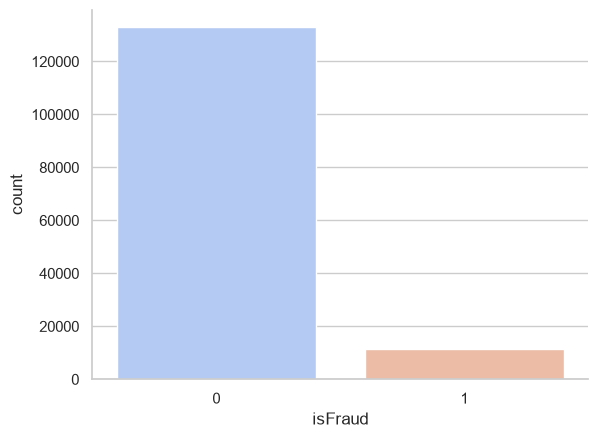

In [12]:
#visualisation des résultats
import seaborn as sns
sns.set(style="whitegrid")
sns.countplot(x='isFraud', data=data, palette='coolwarm')
sns.despine()

In [13]:
#le montant moyen des transactions frauduleuses
mean_fraud_amount = data[data['isFraud'] == 1]['TransactionAmt'].mean()
print("Montant moyen des transactions frauduleuses :", round(mean_fraud_amount, 2), "€")

Montant moyen des transactions frauduleuses : 88.81 €


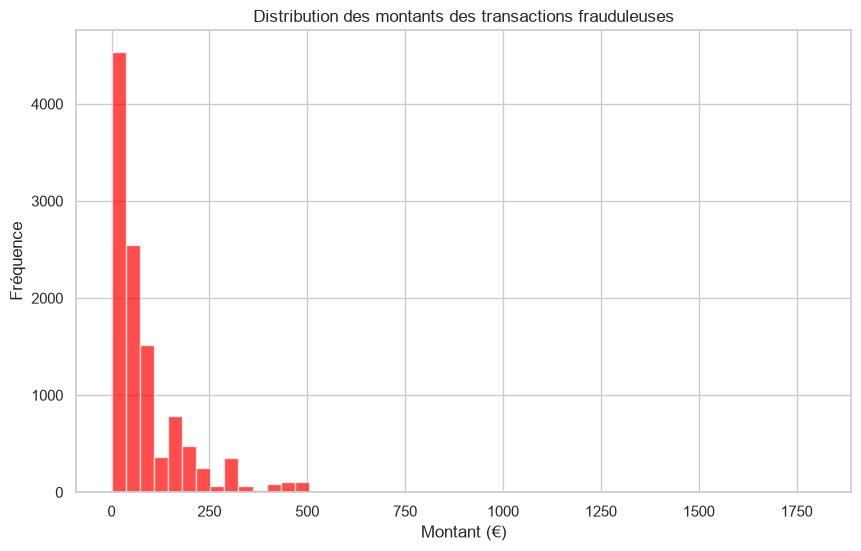

In [14]:
#visualisation de la distribution des montants des transactions frauduleuses
distribution_fraud = data[data['isFraud'] == 1]['TransactionAmt']
plt.figure(figsize=(10, 6))
plt.hist(distribution_fraud, bins=50, color='red', alpha=0.7)
plt.title('Distribution des montants des transactions frauduleuses')
plt.xlabel('Montant (€)')
plt.ylabel('Fréquence')
plt.show()
#on voit que la courbe ne suit pas une distribution normale, mais plutôt une distribution asymétrique avec une longue queue à droite.
#ce qui indique que les montants des transactions frauduleuses ne sont pas dûs au hasard, mais plutôt à des comportements spécifiques de fraude.

C:\Users\lucre\AppData\Local\Temp\ipykernel_45244\1854322620.py:1: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(distribution_fraud, vert=False)


Text(0.5, 1.0, 'Boxplot des montants des transactions frauduleuses')

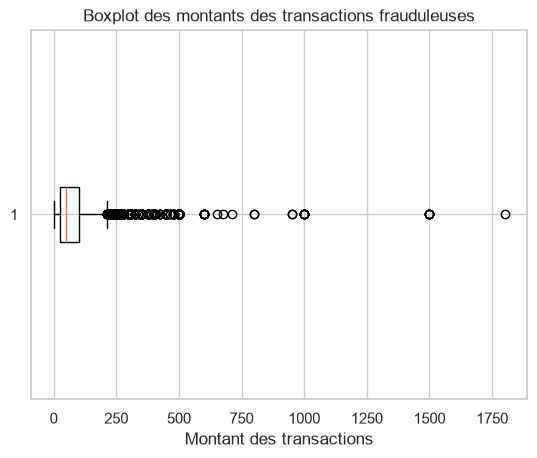

In [15]:
plt.boxplot(distribution_fraud, vert=False)
plt.xlabel('Montant des transactions')
plt.title('Boxplot des montants des transactions frauduleuses')
#on voit qu'une majorité des transactions frauduleuses se retrouvent dans la tranche de 0 à 250€

## Analyse statistique
On a vu plus haut qu'on avait moins de 5% des transactions qui étaients frauduleuses, pour un montant moyen de 88$. Egalement que les montants des transactions frauduleuses se trouve généralement dans la plage de 0 - 250$, et donc qu'ils ne suivent pas une distribution normale et ne sont pas dûes au hasard.

Ici on va chercher à comprendre les comportements qui influence les transactions frauduleuses par des tests statistiques.

**Différents test statistiques à utiliser**
- Anova, compare la moyenne de 3 ou plusieurs groupes. On l'utilise quand les données sont continues, et approxivement normal
- Chi-test permet de tester l'association entre les variables catégorielles. Utile quand les données sont catégorielles et dans les large sample
- Mann-Withney U test, compare 2 groupes indépendants. Utilse quand les données sont ordinal ou non distribués normalement.
- Fisher's Exact Test, test les associations entre les variables categorielles. Utile pour les petis jeux de données
- Wilcoxon test, compare 2 groupes reliés. Utile quand les données sont paired mais pas distribuées normalement.
- Pearson Correlation, mesure la corelation linéaire entre 2 variables continues. Utile quand les données sont continues et approxivement normal.


In [16]:
fraud = data[data['isFraud'] == 1]
fraud 

,TransactionID,isFraud,TransactionDT,TransactionAmt,ProductCD,card1,card2,card3,card4,card5,...,id_31,id_32,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
52,2987240,1,90193,37.098,C,13413,103.0,185.0,visa,137.0,...,chrome 54.0 for android,24.0,1920x1080,match_status:2,F,F,T,T,mobile,Redmi Note 4 Build/MMB29M
53,2987243,1,90246,37.098,C,13413,103.0,185.0,visa,137.0,...,chrome 54.0 for android,24.0,1920x1080,match_status:2,F,F,T,T,mobile,Redmi Note 4 Build/MMB29M
54,2987245,1,90295,37.098,C,13413,103.0,185.0,visa,137.0,...,chrome 54.0 for android,24.0,1920x1080,match_status:2,F,F,T,T,mobile,Redmi Note 4 Build/MMB29M
69,2987288,1,90986,155.521,C,16578,545.0,185.0,visa,226.0,...,chrome 62.0 for ios,24.0,1920x1080,match_status:2,F,F,F,F,mobile,Windows
86,2987367,1,92350,225.000,R,4425,562.0,150.0,mastercard,197.0,...,firefox,24.0,1440x900,match_status:2,T,F,T,F,desktop,rv:52.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
144202,3577351,1,15807131,125.665,C,3289,176.0,185.0,mastercard,224.0,...,chrome 66.0 for android,24.0,1920x1080,match_status:2,F,F,T,F,mobile,SM-G610F Build/NRD90M
144203,3577354,1,15807171,125.665,C,14337,228.0,106.0,visa,137.0,...,chrome 66.0 for android,24.0,1920x1080,match_status:2,F,F,T,F,mobile,SM-G610F Build/NRD90M
144204,3577364,1,15807516,69.964,C,5812,408.0,185.0,mastercard,224.0,...,samsung browser 6.4,24.0,1920x1080,match_status:2,F,F,T,F,mobile,SAMSUNG SM-J700M Build/MMB29K
144206,3577368,1,15807677,100.000,H,6758,399.0,150.0,american express,146.0,...,mobile safari 11.0,32.0,2208x1242,match_status:1,T,F,F,T,mobile,iOS Device


In [17]:
#les caractéristiques non categorielles des transactions frauduleuses sont les suivantes :
fraud.describe()

,TransactionID,isFraud,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,...,id_06,id_09,id_10,id_11,id_13,id_14,id_17,id_19,id_20,id_32
count,1.131800e+04,11318.0,1.131800e+04,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,...,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000,11318.000000
mean,3.293289e+06,1.0,7.640322e+06,88.810342,9280.986128,363.053896,171.546916,184.050716,298.532073,86.339901,...,-7.970136,0.121576,-0.145874,99.777659,47.593038,-306.223714,204.054338,331.401131,437.642516,25.133062
std,1.625708e+05,0.0,4.440934e+06,107.991313,4777.945008,164.194194,18.277104,46.661665,58.823459,4.876394,...,16.770493,1.050409,1.221373,1.006052,11.966986,66.203689,30.061111,124.978473,138.964241,2.861561
min,2.987240e+06,1.0,9.019300e+04,0.292000,1015.000000,100.000000,100.000000,100.000000,110.000000,10.000000,...,-100.000000,-13.000000,-31.000000,90.000000,11.000000,-600.000000,100.000000,100.000000,100.000000,0.000000
25%,3.161441e+06,1.0,3.784516e+06,25.000000,5009.000000,177.000000,150.000000,138.000000,299.000000,87.000000,...,-9.000000,0.000000,0.000000,100.000000,49.000000,-300.000000,166.000000,266.000000,325.000000,24.000000
50%,3.285446e+06,1.0,7.370668e+06,50.000000,9633.000000,399.000000,185.000000,219.000000,299.000000,87.000000,...,0.000000,0.000000,0.000000,100.000000,52.000000,-300.000000,225.000000,290.000000,507.000000,24.000000
75%,3.423267e+06,1.0,1.103941e+07,100.032250,13809.000000,520.000000,185.000000,226.000000,299.000000,87.000000,...,0.000000,0.000000,0.000000,100.000000,52.000000,-300.000000,225.000000,417.000000,549.000000,24.000000
max,3.577526e+06,1.0,1.581088e+07,1800.000000,18375.000000,599.000000,231.000000,237.000000,536.000000,96.000000,...,0.000000,8.000000,0.000000,100.000000,64.000000,540.000000,226.000000,667.000000,657.000000,32.000000


In [18]:
#les caractéristiques categorielles des transactions frauduleuses sont les suivantes :
fraud.describe(include=['object'])

,ProductCD,card4,card6,P_emaildomain,R_emaildomain,id_12,id_15,id_16,id_28,id_29,id_30,id_31,id_33,id_34,id_35,id_36,id_37,id_38,DeviceType,DeviceInfo
count,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318,11318
unique,4,4,2,32,32,2,3,2,2,2,59,99,59,3,2,2,2,2,2,420
top,C,visa,credit,gmail.com,gmail.com,NotFound,Found,Found,Found,Found,Windows 10,chrome 63.0,1920x1080,match_status:2,F,F,T,F,desktop,Windows
freq,7640,6982,6705,7227,7060,10049,7214,8278,7933,7927,8533,1650,8445,10191,7745,11074,9298,7325,5661,5832


Text(0.5, 1.0, 'Distribution des transactions frauduleuses par ProductCD ')

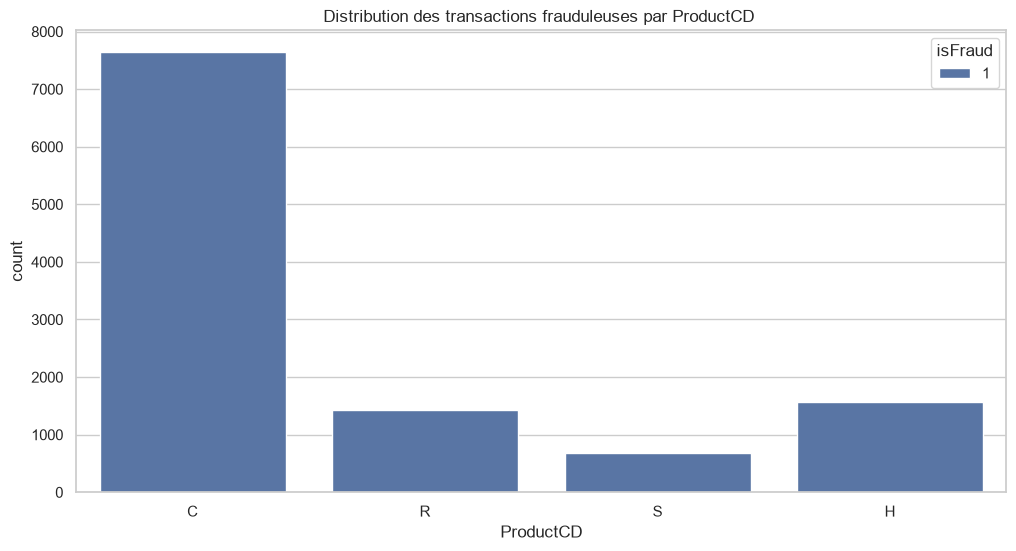

In [19]:
#visualisation des résultats
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.countplot(x='ProductCD', hue='isFraud', data=fraud)
plt.title('Distribution des transactions frauduleuses par ProductCD ')

Text(0.5, 1.0, 'Distribution des transactions frauduleuses par type de Carte Card4 ')

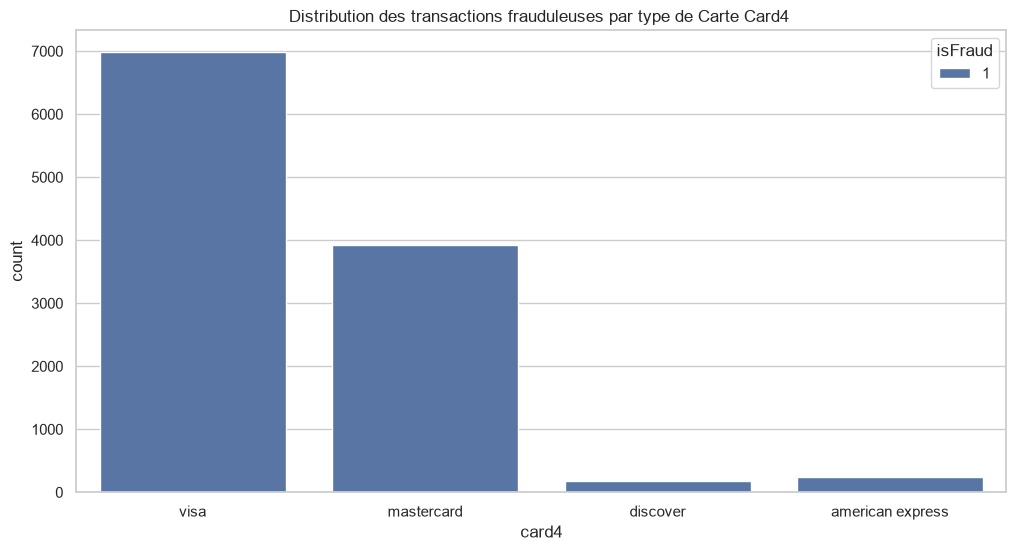

In [20]:
#visualisation des résultats
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.countplot(x='card4', hue='isFraud', data=fraud)
plt.title('Distribution des transactions frauduleuses par type de Carte Card4 ')

Text(0.5, 1.0, 'Distribution des transactions frauduleuses par type de Compte Card6 ')

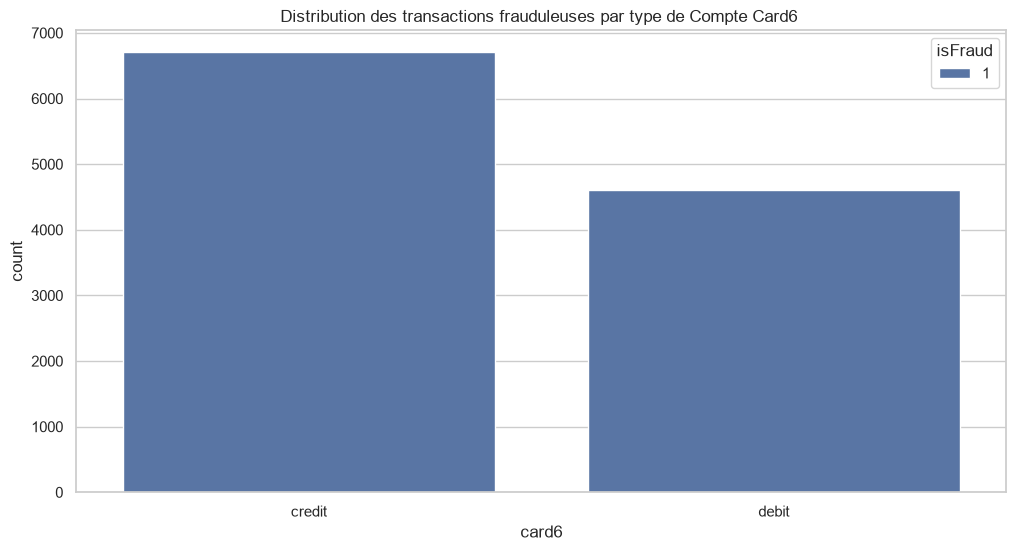

In [21]:
#visualisation des résultats
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.countplot(x='card6', hue='isFraud', data=fraud)
plt.title('Distribution des transactions frauduleuses par type de Compte Card6 ')

C:\Users\lucre\AppData\Local\Temp\ipykernel_45244\789500959.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_counts.index[0:10], y=domain_counts.values[0:10], palette='viridis')


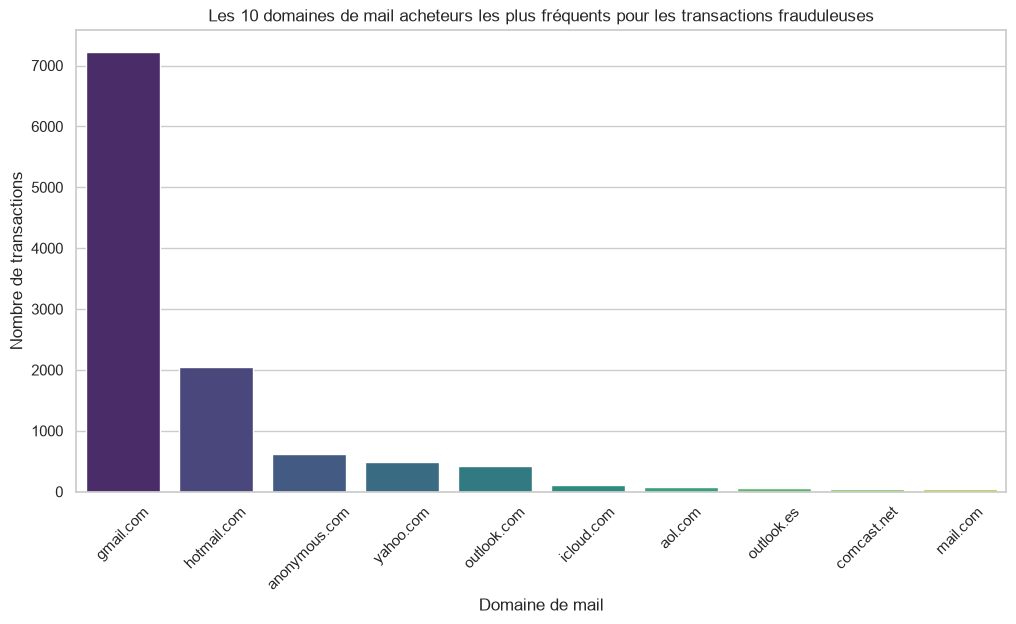

In [22]:
#le domaine des mails le plus fréquent pour les transactions frauduleuses est le suivant :
domain_counts = fraud['P_emaildomain'].value_counts()
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.barplot(x=domain_counts.index[0:10], y=domain_counts.values[0:10], palette='viridis')
plt.title('Les 10 domaines de mail acheteurs les plus fréquents pour les transactions frauduleuses')
plt.xlabel('Domaine de mail')
plt.ylabel('Nombre de transactions')
plt.xticks(rotation=45)
plt.show()

C:\Users\lucre\AppData\Local\Temp\ipykernel_45244\1471264921.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=domain_r_counts.index[:10], y=domain_r_counts.values[:10] , palette='viridis')


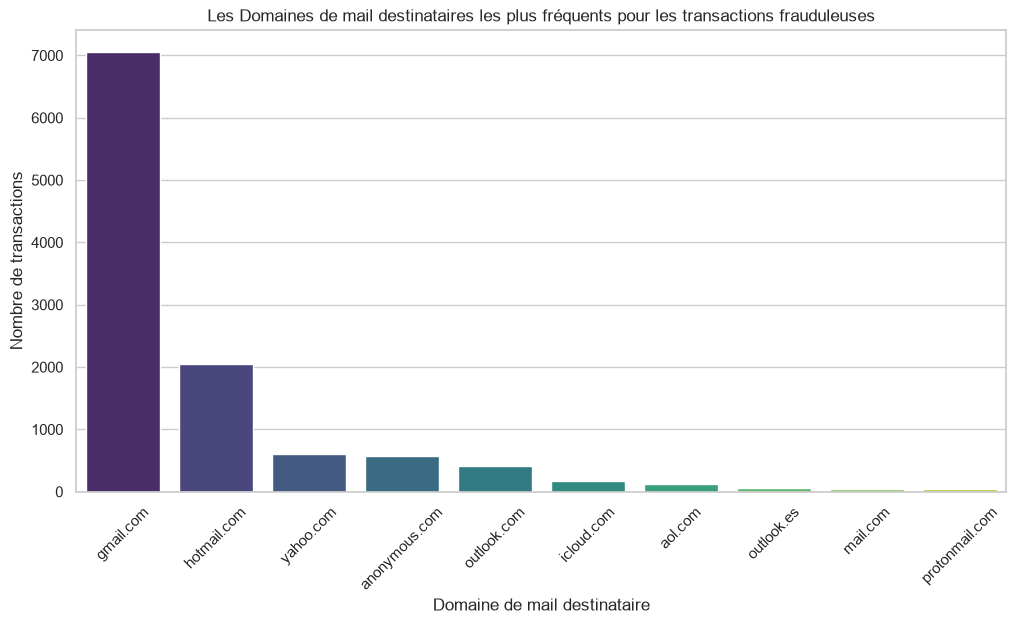

In [23]:
#le domaine des mails le plus fréquent pour les transactions frauduleuses est le suivant :
domain_r_counts = fraud['R_emaildomain'].value_counts()
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.barplot(x=domain_r_counts.index[:10], y=domain_r_counts.values[:10] , palette='viridis')
plt.title('Les Domaines de mail destinataires les plus fréquents pour les transactions frauduleuses')
plt.xlabel('Domaine de mail destinataire')
plt.ylabel('Nombre de transactions')
plt.xticks(rotation=45)
plt.show()

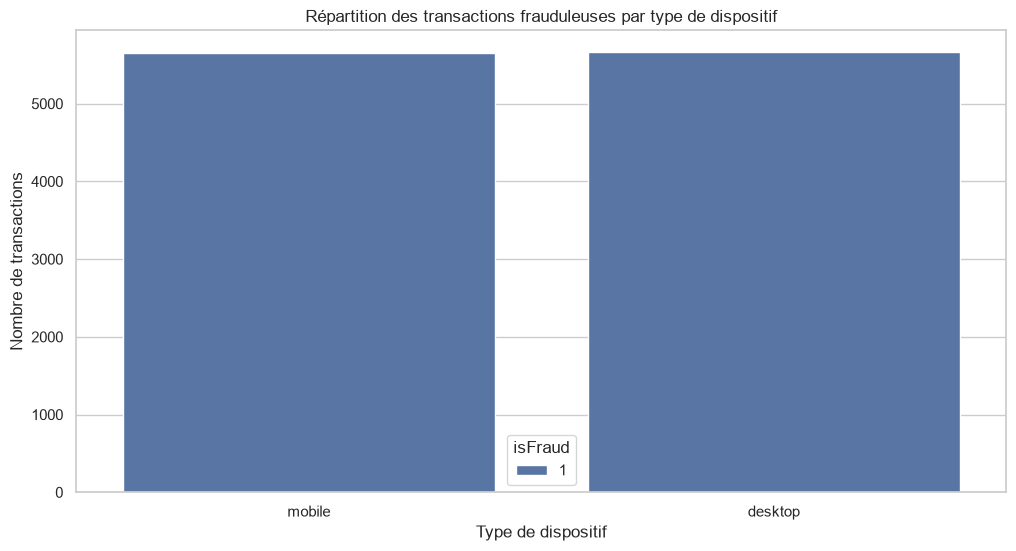

In [24]:
sns.set(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.countplot(x='DeviceType', hue='isFraud', data=fraud)
plt.title('Répartition des transactions frauduleuses par type de dispositif')
plt.xlabel('Type de dispositif')
plt.ylabel('Nombre de transactions')
plt.show()

On voit que les transactions frauduleuses ont plusieurs caractéristiques:
- elles proviennent principalement d'utilisateurs ayant une adresse gmail et hotmail, pour des destinataires ayant des adresses gmail et hotmail
- au niveau des produits qui sont utilisés pour les transacations frauduleuses ils sont principalement ceux de la catégorie C et H
- Le type de carte le plus utilisé dans les transactions frauduleuses sont les cartes visa suivi par les cartes mastercard
- les comptes les plus utilisés sont les comptes de débit suivi par les comptes de crédit
- enfin elles se font principalement par mobile ou ordinateur

Pour les autres données au vu du nombre de colonne qui est important et du temps de calcul on va opté pour l'application des PCA afin de déterminer les composantes les plus importantes pour la détection de transaction frauduleuses.

## PCA: Principale Components Analysis

C'est une technique de réduction de dimensionnalité qui transforme un ensemble de données en un ensemble de composantes orthogonales. Il simplifie des ensembles de données complexes tout en préservant leurs structures les plus importantes.

**5 étapes**
- *etape 1*: normalisation et recentrage des données: le but est de standardiser l'étendue des variables initiales continues afin que chacune contribue à l'analyse. On met tout à la même échelle.
- *etape 2*: calcul de la matrice de covariance: comprendre comment les varaibles de l'ensemble de données d'entrée varient de la moyenne les unes par rapport aux autres.Voir s'il existe une quelconque relation entre elles. Covariance positif => les deux variables augmentent/diminuent ensemble, covariance negatif => l'un augmente quand l'autre diminue.
- *etape 3* : décomposition des gènes propres et identification des composants principaux. Les vecteurs propres et valeurs propres sont les concepts d'algèbre linéaire qu'on calcule à partir de la matrice de covariance pour déterminer les composantes principales des données. Vecteurs propres => directions des axes ou il y'a le plus de variance, valeurs propres => coeficient attachés aux vecteurs propres donnat la quantité de variance supportée dans chaque composante principale.
- *etape4* : sélection des fonctionnalités et création d'un vecteur de caractéristiques. On choisit de conserver toutes ces composante sou d'écarter celles de moindre importance et de former avec les autres une matrice de vecteurs appelés *vecteur de caractéristique*. Elle contient en colonne les vecteurs propres des composantes que nous avons garder
- *etape 5* : utiliser le vecteur de caractéristiques formés à partir des vecteurs propres de la matrice de covariance pour réorienter les données des axes originaux vers ceux représentés par les composantes principales.

**Variantes de PCA**

- *PCA du noyau*, étend le PCA classique pour capturer des structures non linéaires dans les données. Utilse dans le traitement d'images, la reconnaissance de motis et le regroupement non linéaire.

- *ACP clarsemée*, applique des limites au nombre de paramètre actifs aux composantes principales.Les composantes principales sont plus interprétables et robustes dans les scénarios de haute dimension.

- *PCA robuste*, traite la sensibilité de l'ACP classique aux valeurs aberrantes en décomposant la matrice de donnnées en une matrice de bas rang et une matrice clarsemée qui capture les anomalies. Efficace pour les tâches comme la détection de fraude, soustraction en arrière-plan.

- *ACP incrémentaire*, concçue pour les scénarios ou un ensemble de données est trop grand pour tenir dans la mémoire informatique. Adapté au streaming de données ou applications en temps réel

- *ACP probabiliste*, modèle probabiliste de variables latente qui suppose le bruit gaussienn et permet un traitement bayésien complet. Facilite la gestion de base des données manquantes et l'estimation de l'incertitude.

In [25]:
X = data.drop(['isFraud'], axis=1)  # On supprime la colonne cible et les colonnes avec des valeurs manquantes
y = data['isFraud']
    
#scaler = StandardScaler()
scaler = RobustScaler() #on utilise le RobustScaler pour réduire l'impact des valeurs aberrantes sur la normalisation
X_scaled = scaler.fit_transform(X.select_dtypes(include=[np.number])) #on ne garde que les colonnes numériques pour la normalisation

In [26]:
X_scaled

array([[-0.67076233, -0.57654727,  0.        , ...,  1.37267081,
        -1.29213483,  8.        ],
       [-0.67074967, -0.57654381, -0.46950246, ...,  1.86335404,
         0.0411985 ,  8.        ],
       [-0.67074333, -0.57654214,  0.34725743, ...,  0.55279503,
        -1.29962547,  0.        ],
       ...,
       [ 1.19928368,  1.30151937,  0.31977142, ...,  1.52795031,
        -0.29213483,  0.        ],
       [ 1.19929001,  1.30152212,  4.69502462, ...,  0.19254658,
        -0.45318352,  0.        ],
       [ 1.19929951,  1.30153347,  0.2348183 , ...,  0.59627329,
         0.39700375,  0.        ]], shape=(144233, 284))

In [27]:
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

X_train, X_test, y_train, y_test = train_test_split(X_pca, y, test_size=0.3, random_state=42)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

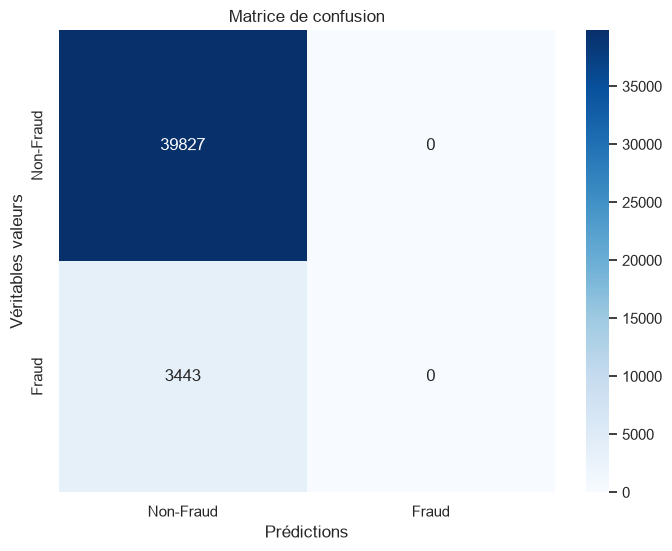

In [28]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Non-Fraud', 'Fraud'], yticklabels=['Non-Fraud', 'Fraud'])
plt.title('Matrice de confusion')
plt.xlabel('Prédictions')
plt.ylabel('Véritables valeurs')
plt.show()

In [29]:
# Conversion des labels en valeurs numériques
"""y_numeric = pd.factorize(y)[0]

fig = plt.figure(figsize=(14, 6))

# --- Avant PCA : 3 features standardisées ---
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
sc1 = ax1.scatter(
    X_scaled[:, 0], X_scaled[:, 1], X_scaled[:, 2],
    c=y_numeric, cmap='coolwarm', edgecolor='k'
)

ax1.set_xlabel('Original Feature 1')
ax1.set_ylabel('Original Feature 2')
ax1.set_zlabel('Original Feature 3')
ax1.set_title('Before PCA: First 3 Standardized Features')
fig.colorbar(sc1, ax=ax1, label='Target classes')

# --- Après PCA : 3 composantes principales ---
ax2 = fig.add_subplot(1, 2, 2, projection='3d')
sc2 = ax2.scatter(
    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],
    c=y_numeric, cmap='coolwarm', edgecolor='k', s=80
)

ax2.set_xlabel('Principal Component 1')
ax2.set_ylabel('Principal Component 2')
ax2.set_zlabel('Principal Component 3')
ax2.set_title('After PCA: First 3 Principal Components')
fig.colorbar(sc2, ax=ax2, label='Target classes')

plt.tight_layout()
plt.show()"""


"y_numeric = pd.factorize(y)[0]\n\nfig = plt.figure(figsize=(14, 6))\n\n# --- Avant PCA : 3 features standardisées ---\nax1 = fig.add_subplot(1, 2, 1, projection='3d')\nsc1 = ax1.scatter(\n    X_scaled[:, 0], X_scaled[:, 1], X_scaled[:, 2],\n    c=y_numeric, cmap='coolwarm', edgecolor='k'\n)\n\nax1.set_xlabel('Original Feature 1')\nax1.set_ylabel('Original Feature 2')\nax1.set_zlabel('Original Feature 3')\nax1.set_title('Before PCA: First 3 Standardized Features')\nfig.colorbar(sc1, ax=ax1, label='Target classes')\n\n# --- Après PCA : 3 composantes principales ---\nax2 = fig.add_subplot(1, 2, 2, projection='3d')\nsc2 = ax2.scatter(\n    X_pca[:, 0], X_pca[:, 1], X_pca[:, 2],\n    c=y_numeric, cmap='coolwarm', edgecolor='k', s=80\n)\n\nax2.set_xlabel('Principal Component 1')\nax2.set_ylabel('Principal Component 2')\nax2.set_zlabel('Principal Component 3')\nax2.set_title('After PCA: First 3 Principal Components')\nfig.colorbar(sc2, ax=ax2, label='Target classes')\n\nplt.tight_layout()\np

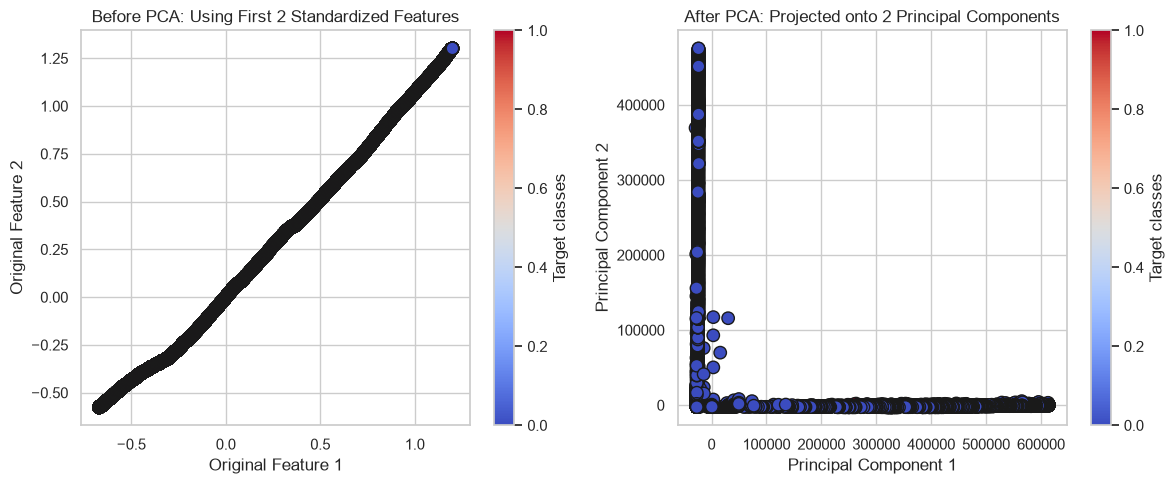

In [30]:
#on vérifie avec pca =2
#pca = PCA(n_components=2)
#X_pca = pca.fit_transform(X_scaled)
y_numeric = pd.factorize(y)[0]

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=y_numeric, cmap='coolwarm', edgecolor='k',s=80)
plt.xlabel('Original Feature 1')
plt.ylabel('Original Feature 2')
plt.title('Before PCA: Using First 2 Standardized Features')
plt.colorbar(label='Target classes')

plt.subplot(1, 2, 2)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y_numeric, cmap='coolwarm', edgecolor='k', s=80)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('After PCA: Projected onto 2 Principal Components')
plt.colorbar(label='Target classes')

plt.tight_layout()
plt.show()

In [31]:
#on affiche les pca et ce à quoi elles correspondent
#("Variance expliquée par composante :", pca.explained_variance_ratio_)
#print("Variance totale expliquée :", pca.explained_variance_ratio_.sum())
print("Valeurs propres (variance expliquée par chaque composante principale) :",pca.explained_variance_)
print("Vecteur propres (composantes principales) :",pca.components_)

Valeurs propres (variance expliquée par chaque composante principale) : [1.20230894e+10 6.94883914e+08]
Vecteur propres (composantes principales) : [[-1.33075514e-06 -1.26988662e-06 -3.64614318e-07  2.37476063e-08
   7.49891153e-09 -7.45943764e-07  2.94820145e-07 -4.90282492e-07
   6.69892804e-07 -5.98522238e-05 -7.45718846e-05 -4.22307440e-08
  -3.49100321e-05  2.80415400e-31 -3.26290999e-05 -2.35546740e-05
  -4.11856919e-05 -0.00000000e+00 -4.20991650e-05 -4.33058874e-05
  -3.31865869e-05 -4.38088030e-05 -2.15723529e-05 -6.49145427e-05
   7.46491372e-07 -2.25471473e-09 -6.83184166e-06 -1.45676775e-05
  -1.01653023e-05 -3.90545949e-08 -8.98978105e-07 -2.94664554e-07
  -6.57187402e-06 -1.23440831e-05 -9.15463289e-06 -2.10689695e-07
  -1.31134224e-06 -7.04296097e-07 -0.00000000e+00 -1.81998532e-08
  -1.86909489e-08 -1.85680082e-08 -2.06776701e-08 -2.07987396e-08
  -2.10621935e-08 -3.28871378e-08 -3.65374931e-08 -3.45794746e-08
  -5.07812733e-09 -5.54308876e-09 -5.34157171e-09 -2.8882300

In [32]:
df_eigenvectors = pd.DataFrame(pca.components_, 
                               columns=X.select_dtypes(include=[np.number]).columns,
                               index=[f'PC{i+1}' for i in range(pca.n_components_)])
print("Vecteurs propres (composantes principales) :")
df_eigenvectors

Vecteurs propres (composantes principales) :


,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,id_06,id_09,id_10,id_11,id_13,id_14,id_17,id_19,id_20,id_32
PC1,-0.000001,-0.000001,-3.646143e-07,2.374761e-08,7.498912e-09,-7.459438e-07,2.948201e-07,-4.902825e-07,6.698928e-07,-0.000060,...,9.354635e-07,1.552976e-07,2.702851e-08,-3.416816e-08,5.633061e-07,-0.000054,-8.664419e-07,3.196050e-07,-3.372913e-07,0.000004
PC2,0.000003,0.000003,1.917086e-06,2.019386e-06,1.018728e-06,-1.220524e-06,-3.224682e-06,6.436772e-06,1.629401e-06,-0.000033,...,4.174858e-06,-1.377018e-07,4.967996e-07,6.655035e-07,9.917454e-07,0.000073,-1.401835e-06,3.796740e-06,1.318040e-06,-0.000004


pca.explained_variance_ indiquent combien de variance chaque composante capture
pca.components pour récupérer les vecteurs propres, ligne = vecteur propre, colonne = contribution d'une feature originale

Chaque vecteur propre est une combinaison linéaire des features oroginales. Les coeficients indiquent l'importance de chaque feature dans la composante. coef fort = feature très importante, coef positif = corrélation positif, et coef negatif = corrélation inverse

In [33]:
#on affiche les composantes principales dont les coeficients sont les plus élevés
df_eigenvectors_abs = df_eigenvectors.abs()
top_features = {}
for pc in df_eigenvectors_abs.index:
    top_features[pc] = df_eigenvectors_abs.loc[pc].nlargest(10).index.tolist()
    print(f"Top 10 features for {pc}: {top_features[pc]}")

Top 10 features for PC1: ['V160', 'V159', 'V165', 'V166', 'V150', 'V164', 'V332', 'V127', 'V212', 'V317']
Top 10 features for PC2: ['V332', 'V127', 'V317', 'V133', 'V212', 'V128', 'V333', 'V308', 'V318', 'V134']


D'après notre PCA, les valeurs les plus importante des PC1 et PCA2 sont les colonnes V160, V159 V165 V166 V150 V164 V332 V127 V212 V317 V332 V127 V317 V133 V212 V128 V333 V308 V318 V314, qui correspondent à des fonctionnalités riches conçues par vesta.

### Methodes de clustering

C'est un algorithme qui fait partie de la catégorie des algorithmes non supervisés qui permettent de repérer des similarités dans les données pour pouvoir ensuite les structurer. Ils peuvent étudier les similarités entre individus ce qui rend la division en différents groupes possible.
Cet algorithme est utile quand on dispose d'un grand volume de données brutes sans segmentation préalable, il permet d'identifier des structures cachées, de mettre en évidence des similitudes invisibles à l'oeil nu et de créer des regroupemenst pertinents pour le métier. Adapter quand les données sont très dispersables et peu comparables entre elles.

Il existe différents types de clustering en fonction du type de distances ( comment on mesure la similarité entre deux individus).
- les méthodes de clustering hiérarchiques; elles forment pas à pas des connexions entre individus et utilisent une matrice de distance entre individus pour trouver le regroupement le plus proche d'un autre.
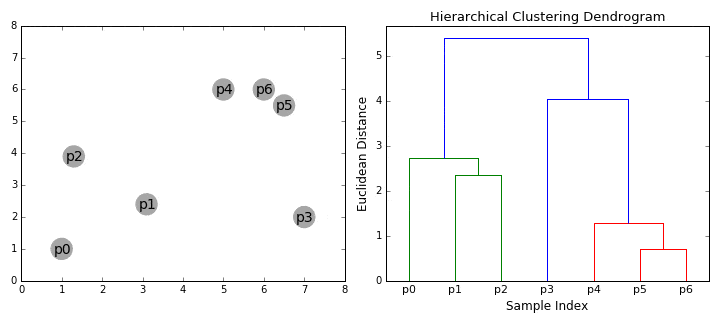

- les méthodes centroïdes, la méthode des k-moyennes. 
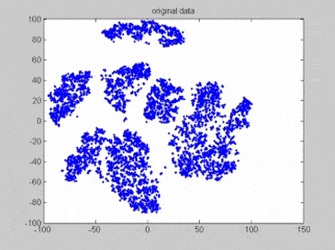

- les méthodes à densité, correspondent aux zones de densité relativement élevées ou beaucoup de points sont proches par rapport à d'autres zones de l'espace R en dimension p.La méthode phare de cette catégorie est appelée « density-based spatial clustering of applications with noise », DBSCAN. En plus de former des classes d’individus, l’algorithme repère par la même occasion les valeurs hors du commun que l’on qualifie de bruit.
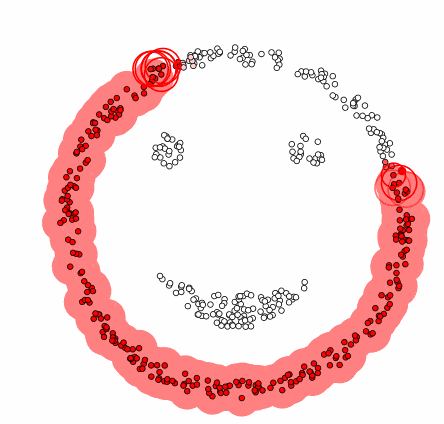

Dans notre cas, avec le PCA on a vu que les deux groupes avaient énormément de distinction et qu'il était difficile d'avoir des groupes bien différents. On part donc sur l'hypothèse selon laquelle les composantes sont très fortement liés entre elles, on ne peut donc pas appliquer la méthode de clustering.On va procéder directement à l'entraînement d'un modèle de machine learning.

### Entrainement des modèles de machine learning
Le but est de prédire la probablité qu'une transaction en ligne soit faudruleuse. Pour ça on va utiliser des algorithmes d'apprentissage supervisé de regression.On va commencer par entrainer un modèle simple de regression linéaire.
Les différents modèles à tester:
- LinearRegression
- LogisticRegression
- RandomForestRegressor
- SVM
- kKneighborsRegressor
- DecisionTreeRegressor
- GradientBoostingRegressor


In [34]:
#split les données en train et test
X = data.drop(['isFraud'], axis=1)  # On supprime la colonne cible et les colonnes avec des valeurs manquantes
y = data['isFraud']
#on remplace les varaibles catégorielles par des variables numériques
X = pd.get_dummies(X, drop_first=True)  # On utilise drop_first=True pour éviter la multicolinéarité

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Taille du jeu d'entraînement :", X_train.shape)
print("Taille du jeu de test :", X_test.shape)


Taille du jeu d'entraînement : (115386, 2670)
Taille du jeu de test : (28847, 2670)


In [35]:
X_train

,TransactionID,TransactionDT,TransactionAmt,card1,card2,card3,card5,addr1,addr2,C1,...,DeviceInfo_verykoolS5019,DeviceInfo_verykoolS5524,DeviceInfo_verykoolS5525,DeviceInfo_verykoolS5530 Build/LMY47I,DeviceInfo_verykools4009,DeviceInfo_verykools5004,DeviceInfo_verykools5034,DeviceInfo_verykools5035,DeviceInfo_vivo,DeviceInfo_xs-Z47b7VqTMxs
1570,2994679,242815,80.479,15885,545.0,185.0,138.0,299.0,87.0,2.0,...,False,False,False,False,False,False,False,False,False,False
44672,3092727,2089630,74.624,9633,296.0,185.0,138.0,299.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
120678,3460576,12243754,50.000,13553,321.0,150.0,226.0,264.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
124951,3485551,13057383,27.850,4537,555.0,141.0,137.0,299.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
53384,3106535,2329696,25.000,2803,100.0,150.0,226.0,264.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110268,3402171,10474633,22.839,13832,375.0,185.0,224.0,299.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
119879,3456604,12101472,28.834,15885,545.0,185.0,138.0,299.0,87.0,2.0,...,False,False,False,False,False,False,False,False,False,False
103694,3374537,9729398,200.000,9043,170.0,150.0,195.0,337.0,87.0,1.0,...,False,False,False,False,False,False,False,False,False,False
131932,3522711,14099955,3.443,5458,266.0,185.0,224.0,299.0,87.0,20.0,...,False,False,False,False,False,False,False,False,False,False


In [36]:
y_train.value_counts()

isFraud
0    106328
1      9058
Name: count, dtype: int64

In [37]:
#on entraine les différents modèles de  regression de machine learning sur les données d'entrainement et on évalue leur performance sur les données de test.
model = LinearRegression()
model.fit(X, y)
y_pred = model.predict(X_test)

# eval du modèle
mean_squared_error_value = mean_squared_error(y_test, y_pred)
r2_score_value = r2_score(y_test, y_pred)
print(f"Mean Squared Error: {mean_squared_error_value}")
print(f"R^2 Score: {r2_score_value}")


Mean Squared Error: 0.05955072779358599
R^2 Score: 0.175272249646386


Mean Squared Error mesure à quel point les prédictions du modèle sont éloignées des vraies valeurs, MSE =0.06 donc la prédiction est parfaite.

R2 Score mesure la proportion de variance du target expliquée par le modèle, ici R2 =0.18 donc le modèle n'explique rien il prédit la moyenne.

In [38]:
#on affiche les coefficients du modèle de regression linéaire
coefficients = pd.DataFrame(model.coef_, X_train.columns, columns=['Coefficient'])
coefficients = coefficients.sort_values(by='Coefficient', ascending=False)
coefficients.head(10)  # Affiche les 10 coefficients les plus élevés

,Coefficient
V222,0.004449
V221,0.004025
V171,0.003012
V229,0.002986
V259,0.002983
V170,0.002593
V230,0.002578
V258,0.002311
V218,0.002144
V228,0.002116


Les 10 colonnes en tête d'après notre regression linéaire sont : V222,V221,V171,V229,V259,V170,V230,V258,V218,V228, ce qui confirme ce que le PCA nous a prédit plus haut dans les principales composantes

In [66]:
#on analyse les prédictions du modèle 
y_pred_converted = (y_pred)  # On arrondit les prédictions pour obtenir des classes binaires
resultats = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred_converted, 'Difference': y_test - y_pred})
resultats.head(10)  # Affiche les 10 premières lignes des résultats

,Actual,Predicted,Difference
46485,0,0.108531,-0.108531
138945,0,-0.071945,0.071945
53023,0,0.085246,-0.085246
4422,0,-0.009995,0.009995
8939,0,0.095806,-0.095806
54532,0,0.042228,-0.042228
94960,0,0.077309,-0.077309
15110,0,0.091444,-0.091444
57011,0,0.110965,-0.110965
96862,1,0.106823,0.893177


In [67]:
mean_error = np.mean(np.abs(resultats['Difference']))
print(f"L'erreur moyenne absolue: {mean_error}")

L'erreur moyenne absolue: 0.1302321908847086


Ici on voit que le moyenne fait en moyenne un erreur de 0.13, donc à chaque résulta prédit il faudrait ajouter 0.13.
L'équation serait : actual = predicted + 0.13

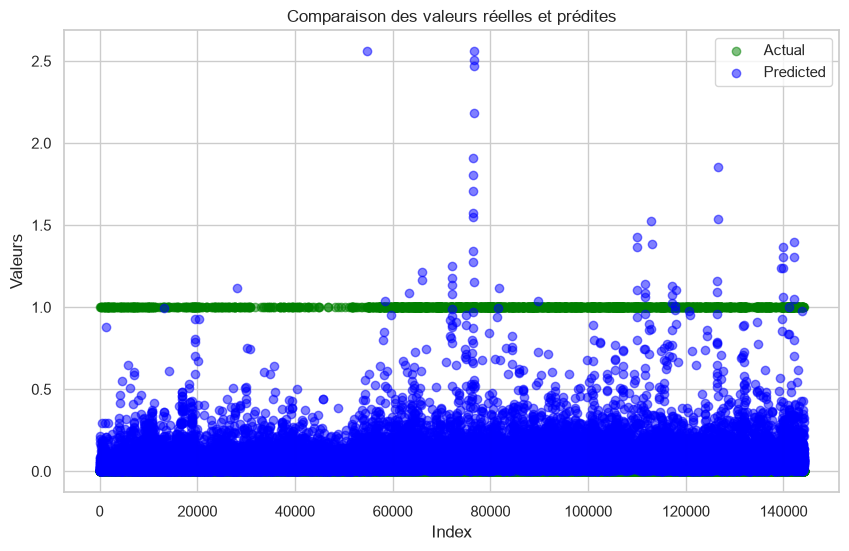

In [41]:
#on affiche les résultats
plt.figure(figsize=(10, 6))
plt.scatter(resultats.index, resultats['Actual'] ,color='green', label='Actual', alpha=0.5)
plt.scatter(resultats.index, resultats['Predicted'], color='blue', label='Predicted', alpha=0.5)
plt.title('Comparaison des valeurs réelles et prédites')
plt.xlabel('Index')
plt.ylabel('Valeurs')
plt.legend()
plt.show()

Dans la majorité des cas, les predictions semblent correspondre aux vrais valeurs, surtout quand il s'agit de la valeur 0. Cela s'explique par le fait que les classes ne sont pas equilibrés, on a largement plus de label 0(pas de fraude) que de label (fraude). Donc le modèle n'arrive pas à bien distinguer quand il n'ya pas fraude. En l'Etat, le modèle ne peut pas être mis en production, car il ferai trop d'erreurs et pourrait ne pas disntinguer quand il y'a fraude.

## CONCLUSION

On a reussi à entraîner un modèle de regression logistique qui nous permet de prédire la probablité qu'une transaction en ligne soit frauduleuse ou pas. Avec une erreur moyenne de 0.06, notre modèle arrive à prédire des probabilité qui correspondent aux valeurs réelles. Mais le modèle n'explique pas la variabilité de notre variables dépendante, avec un R acrré de 0.18, il se contente juste de prédire la moyenne.

Les principaux challenges de ce projet on été au niveau de la compréhension de la  base de donnée, et du déséquilibre au niveau des classes fraud or not fraud. Pour avoir des résultats plus performants et un modèle utilisable avec un plus grand seuil de confiance, il serair pertinent de commencer par expliciter l'interprétentation de chaque colonne. Chaque colonne doit être justifié et correspondre à des informations précises, ensuite il faudrait gérer le problème de déséquilibre des classes. Pour cela différentes méthodes peuvent être appliquées comme le rééchantillonage (le suréchantillonage, sous_échantillonage).
